<a href="https://colab.research.google.com/github/moysessevan/termodinamica-python/blob/main/cod_2_3_diagrama_Tv_agua.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

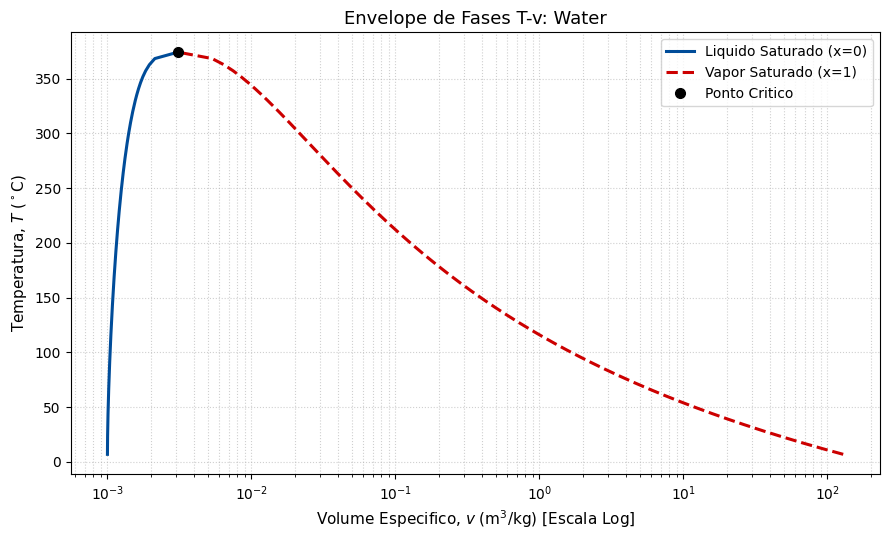

In [1]:
!pip install CoolProp --quiet

import numpy as np
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

fluido = 'Water'

# 1. Propriedades do Ponto Critico
P_crit = PropsSI('Pcrit', fluido)
T_crit = PropsSI('Tcrit', fluido) - 273.15
v_crit = 1.0 / PropsSI('rhocrit', fluido)

# 2. Vetor de 150 pressoes espacadas logaritmicamente (1 kPa ate P_crit)
pressoes = np.logspace(3, np.log10(P_crit - 500), 150)

# 3. Calculo vetorizado via List Comprehension
T_sat = [PropsSI('T', 'P', p, 'Q', 0, fluido) - 273.15 for p in pressoes]
v_f = [1.0 / PropsSI('D', 'P', p, 'Q', 0, fluido) for p in pressoes]
v_g = [1.0 / PropsSI('D', 'P', p, 'Q', 1, fluido) for p in pressoes]

# 4. Plotagem do Diagrama T-v
plt.figure(figsize=(9, 5.5))
plt.plot(v_f, T_sat, color='#004c99', linewidth=2.2, label='Liquido Saturado (x=0)')
plt.plot(v_g, T_sat, color='#cc0000', linestyle='--', linewidth=2.2, label='Vapor Saturado (x=1)')
plt.plot(v_crit, T_crit, 'ko', markersize=7, label='Ponto Critico')

plt.xscale('log')
plt.xlabel(r'Volume Especifico, $v$ ($\mathrm{m^3/kg}$) [Escala Log]', fontsize=11)
plt.ylabel(r'Temperatura, $T$ ($^\circ\mathrm{C}$)', fontsize=11)
plt.title(f'Envelope de Fases T-v: {fluido}', fontsize=13)
plt.grid(True, which='both', linestyle=':', alpha=0.6)
plt.legend(loc='best')
plt.tight_layout()
plt.show()